# FXS / 11 — How big are the moves? Daily pip ranges of the 8 FXS 07 signals (2020 → 2026-11)

Iván (2026-11-12): the average range in pips, every day, for the 8 signals of FXS 07.

Per signal and day (1-minute bid/ask high/low; quoted Dukascopy spread, $3/lot):

| Measure | Meaning |
|---|---|
| **window range** | highest mid − lowest mid while the trade is open (pips) |
| **\|move\|** | \|mid at exit − mid at entry\| (pips), direction ignored |
| **MFE** | best open profit during the trade, at the exit quote (bid for a long, ask for a short) |
| **MAE** | worst open loss during the trade |
| **net** | what the time exit actually made, after spread and commission |
| **day range** | the pair's high − low over the whole New York day (17:00 → 17:00) |

The last columns show how much of the MFE survives to the exit, and how often the MFE reached 5, 10 and 20 pips. Descriptive only.

In [1]:
import json, os, sys, tempfile
import datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

COMMISSION_PER_LOT = 3.0
WINDOWS = ((dt.date(2020, 1, 1), dt.date(2020, 12, 31), "discovery"), (dt.date(2021, 1, 1), dt.date(2025, 12, 31), "confirmation"),
           (dt.date(2026, 1, 1), dt.date(2026, 11, 6), "holdout"))
SIGNALS = {
    "EURUSD-02": ("EURUSD", "NY", 660, 900, -1), "USDJPY-01": ("USDJPY", "UTC", 55, 115, -1), "USDJPY-02": ("USDJPY", "UTC", 25, 55, 1),
    "N-EU-1": ("EURUSD", "NY", 885, 900, -1), "N-UJ-1": ("USDJPY", "UTC", 55, 70, -1), "N-UJ-3": ("USDJPY", "NY", 1340, 1400, 1),
    "N-EJ-1": ("EURJPY", "NY", 1315, 1435, 1), "N-EJ-2": ("EURJPY", "NY", 780, 900, -1)}

SYNTHETIC = os.environ.get("FXS_SYNTHETIC") == "1"
if SYNTHETIC:
    os.environ["EQUITY_TRADING_DIR"] = os.environ.get("FXS_SYNTH_DIR") or tempfile.mkdtemp(prefix="fxs11_")
    os.environ.pop("DUKASCOPY_DIR", None)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "equity_trading").exists())
sys.path.insert(0, str(ROOT / "src"))
from equity_trading import fx_seasonality as F

cfg = F.FXSConfig()
OUT = Path.cwd() / ("11_synthetic" if SYNTHETIC else "11"); OUT.mkdir(exist_ok=True)
PAIRS = sorted({v[0] for v in SIGNALS.values()})
pd.set_option("display.width", 240, "display.max_columns", 40)

## 0. Synthetic inputs (smoke run only)

In [2]:
if SYNTHETIC:
    base = Path(os.environ["EQUITY_TRADING_DIR"]) / "Dukascopy"
    for i, p in enumerate(PAIRS):
        F.write_synthetic_candles(base, p, dt.date(2019, 12, 28), dt.date(2026, 11, 6), seed=81 + i, price=150.0 if p.endswith("JPY") else 1.10)

## 1. Every trade, every day

In [3]:
rows, day_rng = [], []
for a, b, st in WINDOWS:
    dates = pd.bdate_range(a, b)
    for p in PAIRS:
        m = F.load_minutes_ohlc(p, a, b, st, cfg.min_file_share)
        pip = F.pip_size(p)
        mh, ml = 0.5 * (m["bid_h"] + m["ask_h"]).to_numpy(), 0.5 * (m["bid_l"] + m["ask_l"]).to_numpy()
        mc = 0.5 * (m["bid_c"] + m["ask_c"]).to_numpy()
        idx = m.index
        # whole New York day range
        t0, t1 = F.entry_exit_times("NY", 0, 1440, dates)
        for d, x0, x1 in zip(dates, t0, t1):
            i0, i1 = idx.searchsorted(x0), idx.searchsorted(x1)
            if pd.isna(x0) or i1 - i0 < 600 or not m["tick"].to_numpy()[i0:i1].any():
                continue
            day_rng.append({"pair": p, "date": d, "day range": (np.nanmax(mh[i0:i1]) - np.nanmin(ml[i0:i1])) / pip})
        for sig, (pp, clock, s, e, direction) in SIGNALS.items():
            if pp != p:
                continue
            tr = F.run_structure(m, p, clock, s, e, direction, dates, F.NO_STOP, True, COMMISSION_PER_LOT)
            e0, e1 = F.entry_exit_times(clock, s, e, tr["date"])
            i0, i1 = idx.searchsorted(e0), idx.searchsorted(e1)
            wr = np.array([(max(mh[a_:b_].max(), mc[a_ - 1]) - min(ml[a_:b_].min(), mc[a_ - 1])) / pip for a_, b_ in zip(i0, i1)])
            mv = np.abs(mc[i1 - 1] - mc[i0 - 1]) / pip
            rows.append(tr.assign(signal=sig, pair=p, **{"window range": wr, "|move|": mv}))
T = pd.concat(rows, ignore_index=True)
T["year"] = pd.to_datetime(T["date"]).dt.year
DR = pd.DataFrame(day_rng); DR["year"] = pd.to_datetime(DR["date"]).dt.year
T = T[T["window range"] > 0]                     # days without quotes in the window
T.to_parquet(OUT / "11_trades.parquet")
print(T.groupby("signal").size())

signal
EURUSD-02    1779
N-EJ-1       1779
N-EJ-2       1779
N-EU-1       1779
N-UJ-1       1783
N-UJ-3       1779
USDJPY-01    1783
USDJPY-02    1783
dtype: int64


## 2. Average day per signal (2020 → 2026)

In [4]:
def summ(g):
    return pd.Series({"days": len(g), "window range mean": g["window range"].mean(), "window range median": g["window range"].median(),
                      "window range p90": g["window range"].quantile(0.9), "|move| mean": g["|move|"].mean(),
                      "MFE mean": g["best_pips"].mean(), "MFE median": g["best_pips"].median(), "MAE mean": g["worst_pips"].mean(),
                      "net mean": g["net_pips"].mean(), "net st.dev": g["net_pips"].std(), "win rate": (g["net_pips"] > 0).mean(),
                      "MFE >= 5": (g["best_pips"] >= 5).mean(), "MFE >= 10": (g["best_pips"] >= 10).mean(), "MFE >= 20": (g["best_pips"] >= 20).mean(),
                      "MAE <= -10": (g["worst_pips"] <= -10).mean(), "net / MFE": g["net_pips"].mean() / g["best_pips"].mean()})
S = T.groupby("signal").apply(summ).reindex(list(SIGNALS))
S.insert(0, "trade", [f"{'buy' if v[4] > 0 else 'sell'} {v[0]} {F.slot_label(v[1], v[2])} -> {F.slot_label(v[1], v[3]).split()[1]}" for v in SIGNALS.values()])
S.insert(1, "minutes", [v[3] - v[2] for v in SIGNALS.values()])
display(S.round(2)); S.to_csv(OUT / "11_summary.csv")
D = DR.groupby("pair")["day range"].describe(percentiles=[0.1, 0.5, 0.9])
print("whole New York day range (pips):"); display(D.round(1)); D.to_csv(OUT / "11_day_range.csv")

,trade,minutes,days,window range mean,window range median,window range p90,|move| mean,MFE mean,MFE median,MAE mean,net mean,net st.dev,win rate,MFE >= 5,MFE >= 10,MFE >= 20,MAE <= -10,net / MFE
signal,,,,,,,,,,,,,,,,,,
EURUSD-02,sell EURUSD NY 04:00 -> 08:00,240,1779.0,32.74,28.70,53.06,15.73,16.65,12.8,-16.08,1.26,21.73,0.53,0.78,0.61,0.30,0.57,0.08
USDJPY-01,sell USDJPY UTC 00:55 -> 01:55,60,1783.0,24.40,19.85,43.60,12.06,13.22,8.9,-11.18,1.00,18.13,0.53,0.68,0.45,0.21,0.39,0.08
USDJPY-02,buy USDJPY UTC 00:25 -> 00:55,30,1783.0,17.49,14.80,30.40,9.14,8.68,6.3,-8.83,0.56,13.84,0.52,0.57,0.31,0.09,0.31,0.06
N-EU-1,sell EURUSD NY 07:45 -> 08:00,15,1779.0,9.03,7.70,14.50,4.67,4.68,3.6,-4.34,0.24,6.50,0.52,0.36,0.11,0.01,0.07,0.05
N-UJ-1,sell USDJPY UTC 00:55 -> 01:10,15,1783.0,13.61,11.45,25.00,6.88,7.15,4.6,-6.46,0.42,9.87,0.50,0.48,0.25,0.07,0.20,0.06
N-UJ-3,buy USDJPY NY 15:20 -> 16:20,60,1779.0,12.30,9.30,22.42,5.75,5.98,3.9,-6.32,0.30,9.40,0.49,0.41,0.18,0.05,0.15,0.05
N-EJ-1,buy EURJPY NY 14:55 -> 16:55,120,1779.0,19.50,15.65,32.27,9.22,9.29,6.3,-10.25,0.36,15.53,0.50,0.59,0.32,0.11,0.33,0.04
N-EJ-2,sell EURJPY NY 06:00 -> 08:00,120,1779.0,32.32,27.05,53.67,16.03,16.32,11.6,-16.00,0.28,23.56,0.48,0.76,0.56,0.29,0.57,0.02


whole New York day range (pips):


,count,mean,std,min,10%,50%,90%,max
pair,,,,,,,,
EURJPY,1783.0,118.9,70.1,22.0,55.3,101.4,203.8,702.9
EURUSD,1783.0,76.5,37.7,14.0,38.7,68.2,122.8,341.4
USDJPY,1783.0,111.1,75.8,13.2,42.8,92.7,197.0,690.8


## 3. By year

Mean window range, MFE and net pips per year.

In [5]:
for col in ("window range", "best_pips", "worst_pips", "net_pips"):
    y = T.pivot_table(index="signal", columns="year", values=col, aggfunc="mean").reindex(list(SIGNALS))
    print({"best_pips": "MFE", "worst_pips": "MAE", "net_pips": "net"}.get(col, col), "(pips, mean)"); display(y.round(2))
    y.to_csv(OUT / f"11_by_year_{col.replace(' ', '_')}.csv")
display(DR.pivot_table(index="pair", columns="year", values="day range", aggfunc="mean").round(1))

window range (pips, mean)


year,2020,2021,2022,2023,2024,2025,2026
signal,,,,,,,
EURUSD-02,39.54,27.29,46.24,31.28,24.77,32.84,26.23
USDJPY-01,16.64,11.83,29.38,27.13,31.70,31.58,22.24
USDJPY-02,12.44,8.67,21.80,19.86,21.22,20.99,17.46
N-EU-1,10.49,7.97,13.04,8.44,6.68,9.06,7.25
N-UJ-1,8.65,6.96,16.26,15.18,16.83,18.42,12.88
N-UJ-3,10.45,6.53,13.79,12.01,13.96,16.14,13.36
N-EJ-1,18.57,11.48,22.79,19.10,22.64,23.10,18.72
N-EJ-2,28.13,20.66,44.25,35.44,34.94,33.97,28.25


MFE (pips, mean)


year,2020,2021,2022,2023,2024,2025,2026
signal,,,,,,,
EURUSD-02,20.53,14.60,23.76,15.78,12.56,15.41,13.45
USDJPY-01,10.17,6.24,16.50,14.28,16.68,16.61,11.87
USDJPY-02,6.74,4.72,11.46,9.19,10.22,10.04,8.33
N-EU-1,4.70,4.34,7.19,4.63,3.36,4.46,4.01
N-UJ-1,4.50,3.50,9.05,8.21,9.09,9.25,6.32
N-UJ-3,4.07,2.61,6.98,5.88,7.06,8.93,6.39
N-EJ-1,9.14,5.11,10.72,9.19,10.45,11.38,8.97
N-EJ-2,13.30,10.42,22.90,17.52,16.20,18.95,14.74


MAE (pips, mean)


year,2020,2021,2022,2023,2024,2025,2026
signal,,,,,,,
EURUSD-02,-19.01,-12.69,-22.47,-15.51,-12.21,-17.43,-12.78
USDJPY-01,-6.46,-5.58,-12.90,-12.85,-15.05,-14.96,-10.36
USDJPY-02,-5.70,-3.96,-10.36,-10.68,-11.03,-11.00,-9.14
N-EU-1,-5.78,-3.62,-5.86,-3.82,-3.32,-4.61,-3.23
N-UJ-1,-4.15,-3.44,-7.23,-6.97,-7.74,-9.17,-6.55
N-UJ-3,-6.37,-3.91,-6.84,-6.14,-6.93,-7.20,-6.99
N-EJ-1,-9.46,-6.42,-12.06,-10.00,-12.20,-11.74,-9.79
N-EJ-2,-14.84,-10.23,-21.34,-17.93,-18.76,-15.02,-13.49


net (pips, mean)


year,2020,2021,2022,2023,2024,2025,2026
signal,,,,,,,
EURUSD-02,0.52,1.81,4.11,1.24,0.25,0.10,0.68
USDJPY-01,2.92,0.43,1.74,0.23,0.84,1.28,-0.73
USDJPY-02,0.49,0.86,2.17,-0.15,0.97,-0.27,-0.25
N-EU-1,-1.21,0.84,1.02,0.88,0.04,-0.20,0.31
N-UJ-1,0.06,-0.01,1.59,0.62,0.64,0.32,-0.37
N-UJ-3,-1.77,-0.58,1.15,0.68,0.69,1.86,0.06
N-EJ-1,-0.47,-0.78,1.49,0.88,0.75,0.61,-0.05
N-EJ-2,-1.82,0.42,2.34,0.23,-2.77,3.11,0.49


year,2020,2021,2022,2023,2024,2025,2026
pair,,,,,,,
EURJPY,95.0,70.6,151.3,134.2,141.7,127.7,110.3
EURUSD,84.5,63.0,102.2,77.0,61.2,81.4,64.1
USDJPY,73.0,57.9,137.7,129.9,139.6,134.9,103.5


## 4. Distributions

For each signal: window range, MFE and the final net result per trade. The gap between MFE and net is how much of the open profit the fixed exit time gives back.

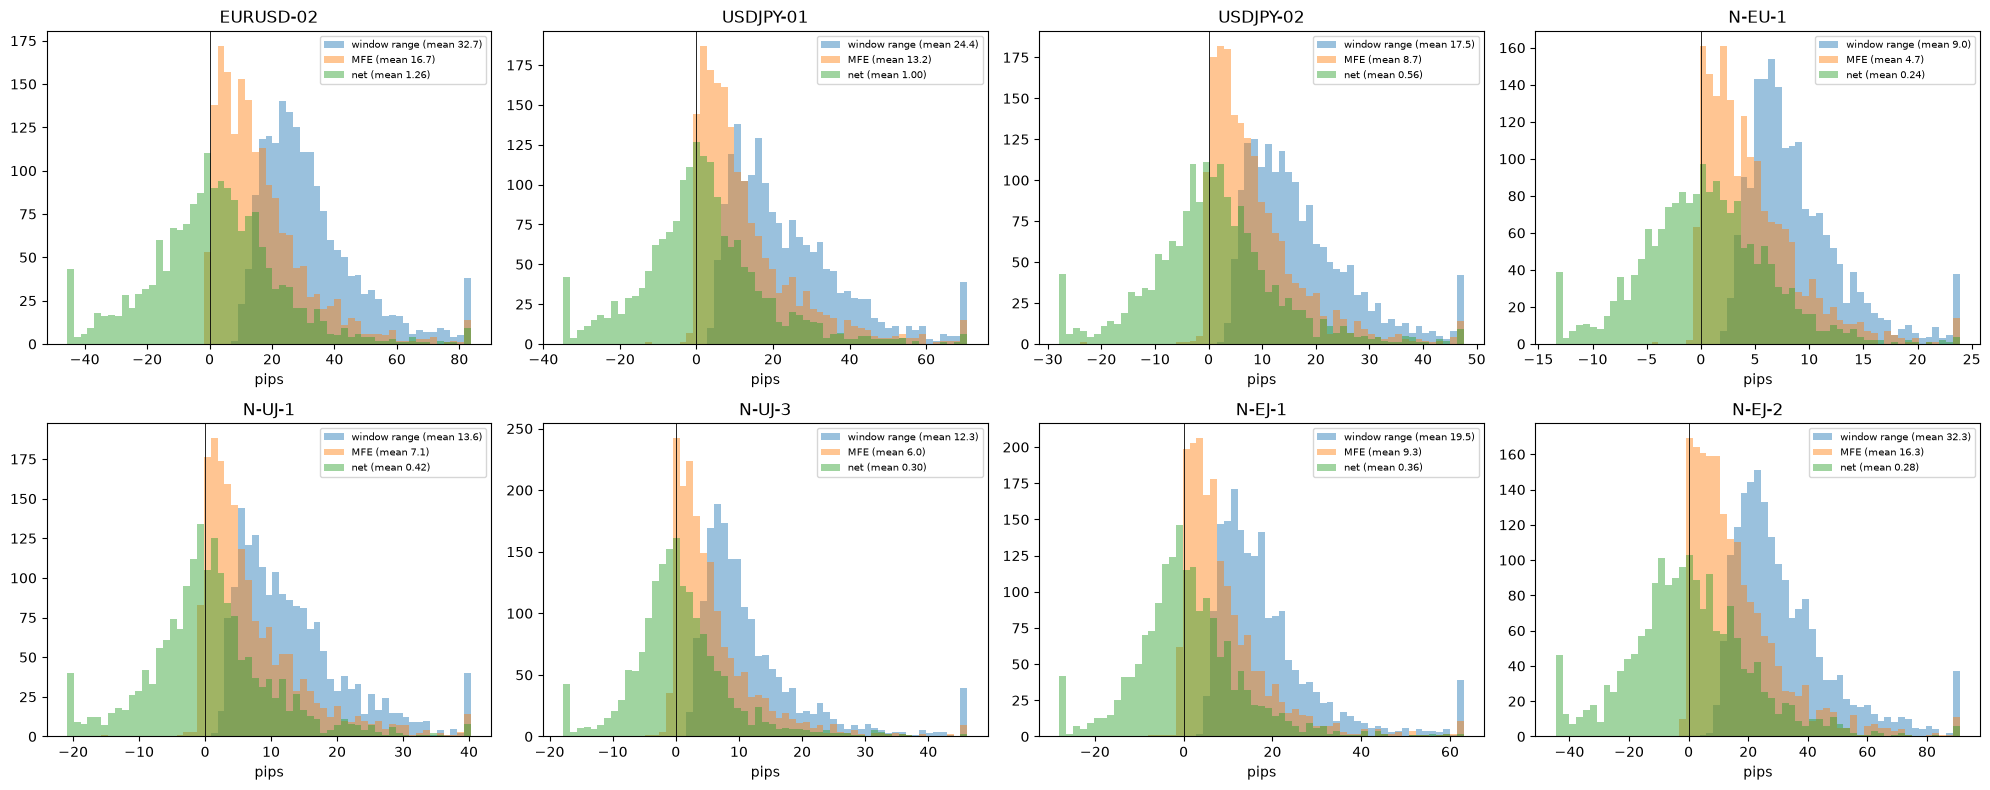

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, sig in zip(axes.ravel(), SIGNALS):
    g = T[T["signal"] == sig]
    hi = g["window range"].quantile(0.98)
    bins = np.linspace(min(g["net_pips"].quantile(0.02), 0), hi, 60)
    ax.hist(g["window range"].clip(upper=hi), bins=bins, alpha=0.45, label=f"window range (mean {g['window range'].mean():.1f})")
    ax.hist(g["best_pips"].clip(upper=hi), bins=bins, alpha=0.45, label=f"MFE (mean {g['best_pips'].mean():.1f})")
    ax.hist(g["net_pips"].clip(lower=bins[0], upper=hi), bins=bins, alpha=0.45, label=f"net (mean {g['net_pips'].mean():.2f})")
    ax.axvline(0, color="black", lw=0.6); ax.set_title(sig); ax.legend(fontsize=7); ax.set_xlabel("pips")
plt.tight_layout(); plt.savefig(OUT / "11_distributions.png", dpi=110); plt.show()

In [7]:
summary = {"study": "FXS11", "descriptive": True, "synthetic": SYNTHETIC, "signals": {k: list(v) for k, v in SIGNALS.items()},
           "summary": S.round(3).reset_index().to_dict(orient="records"), "day_range": D.round(2).reset_index().to_dict(orient="records")}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
print("written", OUT / "summary.json")

written D:\Projects\equity_trading\notebooks\FX_Intraday_Seasonality\Portfolio\11\summary.json
